# 13. Noches A contra el resto: corte calibrado en desarrollo

**Qué hace.** El plan de test (§6.2) categoriza cada noche con la regla de la base sobre los minutos de apnea estimados: 100 o más es A, de 5 a 99 es B, menos de 5 es C. En el notebook 12, con sujetos de afuera, esa regla deja las 12 noches de control como B y 6 de las 8 noches B como A, porque F sobreestima la apnea de cada noche. Acá se prueba una clasificación en **dos** clases, **A contra el resto**, con un corte sobre el **porcentaje de minutos marcados como apnea** elegido con las noches de desarrollo. F y su umbral por minuto no cambian, y tampoco el acierto por registro ni la hipótesis principal: esto solo agrega un resultado secundario.

**Por qué dos clases y por qué esta división (decisiones de criterio, tomadas antes de correr).**
- La B tiene 7 noches en desarrollo y 3 en test, y es la clase menos consistente con la gravedad clínica: en la 4.1 sus noches van de un AHI de 0,1 a 33. Un corte B/A elegido con 5 o 6 noches sería casi ruido. La A, en cambio, es consistente (27 de 28 noches moderadas o graves) y la división queda pareja (28 contra 19 noches en desarrollo, 12 contra 8 en test).
- Se elige "A contra el resto" porque responde la pregunta clínica que importa (si la noche tiene apnea relevante). El problema de las noches de control no se esconde: lo siguen midiendo el sesgo por noche y la fracción de minutos marcados en las noches C (notebook 12).
- **Se declara:** la división se eligió después de ver en el notebook 12 la matriz A/B/C con la regla de la base. Antes se había empezado una versión con tres categorías y dos cortes; se descartó sin mirar sus resultados.

**Reglas (fijadas antes de correr).**
1. **Corte:** los candidatos son los puntos medios entre porcentajes estimados consecutivos de las noches de entrenamiento, más los dos extremos. Se elige el que deja más noches bien clasificadas; si hay empate, el del medio. La clase real se cuenta como en el plan: una noche es A si tiene 100 minutos anotados con apnea o más, sobre los minutos evaluados. Se usa el porcentaje y no los minutos porque las noches evaluadas tienen largos distintos.
2. **Validación:** los mismos 5 grupos de sujetos del notebook 12 y la misma elección anidada. En cada grupo, el corte se elige con las noches de entrenamiento (con el umbral de ese grupo, que ya se ajustó con ellas: un poco optimista, se declara) y se aplica a las de afuera.
3. **Comparación:** contra la regla de la base llevada a dos clases (A si los minutos estimados son 100 o más). **Se adopta si sube el porcentaje de noches de afuera bien clasificadas, con el intervalo de confianza de la diferencia completo por encima de 0** (bootstrap por sujeto, 2.000 remuestreos). La decisión se toma con F; si se adopta, la referencia usa su propio corte, elegido igual.
4. **En test**, pase lo que pase acá, se reporta la matriz A/B/C de la regla de la base, como estaba fijado. Si el corte se adopta, se agrega "A contra el resto" con el corte calibrado (desvío fechado del plan); si no, se agrega con la regla de la base.

In [1]:
import json
import os
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT)); os.environ["PYTHONPATH"] = str(ROOT)
from src.config import RESULTS_DIR, SPLIT_CSV
from src.evaluation.metrics import apply_a_cut, category_from_minutes, fit_a_cut
from src.features.variants import coupling_variants, hrv_variants
from src.stats.compare import subject_folds
from src.stats.nested import category_agreement_boot, nested_cv

FIG = RESULTS_DIR / "figuras"; FIG.mkdir(parents=True, exist_ok=True)
CACHE = RESULTS_DIR / "e3_v3"
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "font.size": 9,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.8})
AZUL, NARANJA, GRIS, TINTA = "#2a78d6", "#eb6834", "#a3a29c", "#2b2b2b"
COLOR_CAT = {"A": NARANJA, "B": GRIS, "C": AZUL}
split = pd.read_csv(SPLIT_CSV).set_index("record")
DEV = list(split.index[split.set == "dev"])
subject_of = split.loc[DEV, "subject"]
KW = dict(n_boot=1000, n_boot_rec=300, seed=2026)
print(len(DEV), "registros de desarrollo,", subject_of.nunique(), "sujetos")

47 registros de desarrollo, 19 sujetos


In [2]:
f_coup, f_hrv = CACHE / "acoplamiento.parquet", CACHE / "hrv.parquet"
if not (f_coup.exists() and f_hrv.exists()):
    raise FileNotFoundError("Falta la caché de candidatas: correr primero notebooks/12_validacion_anidada.ipynb.")
coup, hrv = pd.read_parquet(f_coup), pd.read_parquet(f_hrv)
wide_c, meta_c = coupling_variants(coup)
wide_h, meta_h = hrv_variants(hrv)
info = coup.groupby(["record", "minute"])[["label", "corrected"]].first()
eval_idx = (wide_c.dropna().index.intersection(wide_h.dropna().index)
            .intersection(info.index[(info.label >= 0) & (info.corrected <= 0.2)]))
y_all = info.loc[eval_idx, "label"].to_numpy(int)
subj_all = subject_of.loc[eval_idx.get_level_values("record")].to_numpy()
folds = subject_folds(pd.Series(y_all, index=subj_all).groupby(level=0).max().astype(bool), k=5)
families = {"F": (wide_c, meta_c), "HRV": (wide_h, meta_h)}
del coup, hrv
print(f"minutos de elección: {len(eval_idx):,} | grupos: {[len(f) for f in folds]} sujetos")

minutos de elección: 22,125 | grupos: [4, 4, 4, 4, 3] sujetos


## Validación anidada con el corte elegido en cada grupo

In [3]:
f_pred, f_ch = CACHE / "categoria_a_pred.parquet", CACHE / "categoria_a_elecciones.parquet"
t0 = time.time()
if f_pred.exists() and f_ch.exists():
    pred, choices = pd.read_parquet(f_pred), pd.read_parquet(f_ch)
    print("recuperado de la caché")
else:
    pred, choices = nested_cv(families, info, subject_of, eval_idx, folds, **KW)
    pred.to_parquet(f_pred); choices.to_parquet(f_ch)
print(f"tiempo: {(time.time() - t0) / 60:.1f} min | minutos evaluados afuera: {len(pred):,}")
choices[["grupo", "familia", "variante", "umbral", "corte_a"]].round(4)

tiempo: 4.7 min | minutos evaluados afuera: 22,275


,grupo,familia,variante,umbral,corte_a
0,1,F,area|240s|welch3|apnea|potencia sola|none|k1,-6.9120,0.2686
1,1,HRV,hrv|180s|apnea|none|k1,0.0014,0.4649
2,2,F,area|240s|welch3|apnea|potencia sola|none|k1,-6.9612,0.2137
3,2,HRV,hrv|240s|lf_hf|none|k1,3.0046,0.3965
4,3,F,area|240s|welch3|apnea|potencia sola|none|k1,-6.9225,0.4799
5,3,HRV,hrv|180s|apnea|none|k1,0.0016,0.4312
6,4,F,area|240s|welch3|apnea|potencia sola|none|k1,-6.9061,0.2808
7,4,HRV,hrv|180s|apnea|none|k1,0.0015,0.4532
8,5,F,area|240s|welch3|apnea|potencia sola|none|k1,-6.9555,0.2755
9,5,HRV,hrv|180s|apnea|none|k1,0.0014,0.4692


In [4]:
g = pred.groupby(level="record")
noches = pd.DataFrame({"subject": subject_of.loc[g.size().index].to_numpy(), "minutos": g.size(),
                       "min_anotados": g["label"].sum()})
noches["categoria"] = [category_from_minutes(m) for m in noches.min_anotados]
noches["real_A"] = noches.categoria == "A"
for fam in ("F", "HRV"):
    noches[f"frac_{fam}"] = g[f"frac_{fam}"].first()
    noches[f"base_{fam}"] = noches[f"frac_{fam}"] * noches.minutos >= 100
    noches[f"corte_{fam}"] = g[f"a_corte_{fam}"].first().astype(bool)
print("Noches por categoría real:", noches.categoria.value_counts().reindex(list("ABC")).to_dict())
res = {fam: category_agreement_boot(noches, "real_A", [f"base_{fam}", f"corte_{fam}"], n_boot=2000)
       for fam in ("F", "HRV")}
for fam, r in res.items():
    print(f"\n{fam}: noches bien clasificadas (A contra el resto)")
    display(r.astype(float).round(3))
r = res["F"].iloc[-1]
ADOPTA = bool(r["ic_lo"] > 0)
print(f"-> regla (F): diferencia {r['acierto']:+.3f} (intervalo {r['ic_lo']:+.3f} a {r['ic_hi']:+.3f}): "
      f"{'se adopta el corte calibrado' if ADOPTA else 'no se adopta el corte calibrado'}")

Noches por categoría real: {'A': 27, 'B': 8, 'C': 12}

F: noches bien clasificadas (A contra el resto)


,acierto,ic_lo,ic_hi
base_F,0.830,NaN,NaN
corte_F,0.766,NaN,NaN
corte_F - base_F,-0.064,-0.196,0.042



HRV: noches bien clasificadas (A contra el resto)


,acierto,ic_lo,ic_hi
base_HRV,0.574,NaN,NaN
corte_HRV,0.660,NaN,NaN
corte_HRV - base_HRV,0.085,-0.116,0.304


-> regla (F): diferencia -0.064 (intervalo -0.196 a +0.042): no se adopta el corte calibrado


F con la regla de la base (100 minutos estimados):


estimada,A,resto
categoría real,,
A,25,2
B,6,2
C,0,12


F con el corte calibrado:


estimada,A,resto
categoría real,,
A,22,5
B,6,2
C,0,12


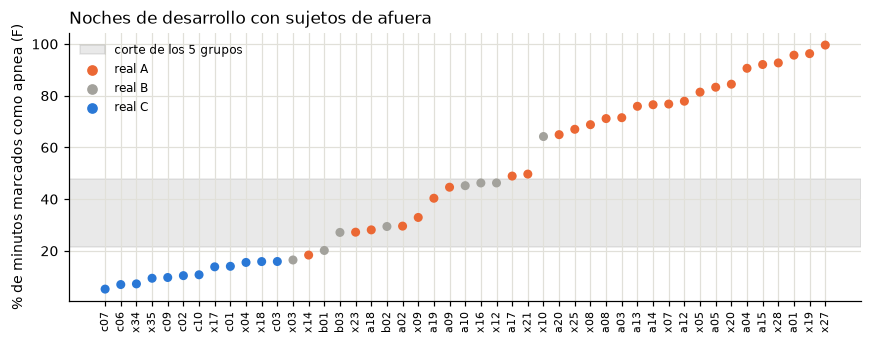

In [5]:
def matriz(est):
    return pd.crosstab(noches.categoria, np.where(est, "A", "resto"),
                       rownames=["categoría real"], colnames=["estimada"])
for fam in ("F",):
    print(f"{fam} con la regla de la base (100 minutos estimados):"); display(matriz(noches[f"base_{fam}"]))
    print(f"{fam} con el corte calibrado:"); display(matriz(noches[f"corte_{fam}"]))

fig, ax = plt.subplots(figsize=(8, 3.2))
o = noches.sort_values("frac_F")
ax.scatter(range(len(o)), 100 * o.frac_F, c=[COLOR_CAT[c] for c in o.categoria], s=24, zorder=3)
cf = choices[choices.familia == "F"]
ax.axhspan(100 * cf.corte_a.min(), 100 * cf.corte_a.max(), color=TINTA, alpha=0.1, label="corte de los 5 grupos")
for c in "ABC":
    ax.scatter([], [], color=COLOR_CAT[c], label=f"real {c}")
ax.set_xticks(range(len(o)), o.index, rotation=90, fontsize=7)
ax.set_ylabel("% de minutos marcados como apnea (F)")
ax.set_title("Noches de desarrollo con sujetos de afuera", loc="left")
ax.legend(frameon=False, fontsize=8)
fig.tight_layout(); fig.savefig(FIG / "13_corte_a.png")

## Corte final con todo desarrollo (para test, si se adopta)

Con F y la referencia congeladas, sus umbrales de `docs/umbrales_desarrollo.json` y los minutos que define el plan (§4). Se calcula siempre, para que el número quede escrito; se usa solo si la regla lo adopta. El acierto de esta celda usa los mismos datos con los que se eligió el corte, así que es optimista.

In [6]:
umb = json.loads((ROOT / "docs" / "umbrales_desarrollo.json").read_text(encoding="utf-8"))
F_COL, H_COL = "area|240s|welch3|apnea|potencia sola", "hrv|180s|vlf"
inf = info[(info.label >= 0) & (info.corrected <= 0.2)]
d = pd.DataFrame({"label": inf.label, "F": wide_c[F_COL].reindex(inf.index),
                  "HRV": wide_h[H_COL].reindex(inf.index)}).dropna()
print(f"minutos evaluados: {len(d):,} (el notebook 11 usó {umb['minutos_ajuste']:,})")
gg = d.groupby(level="record")
fin = pd.DataFrame({"minutos": gg.size(), "min_anotados": gg["label"].sum()})
fin["real_A"] = fin.min_anotados >= 100
cortes = {}
for fam, key in (("F", "F"), ("HRV", "VLF")):
    frac = (d[fam] >= umb["umbrales"][key]).groupby(level="record").mean().loc[fin.index]
    cortes[fam] = fit_a_cut(frac.to_numpy(), fin.real_A.to_numpy())
    ok = (apply_a_cut(frac.to_numpy(), cortes[fam]) == fin.real_A.to_numpy()).mean()
    print(f"{fam}: corte A = {cortes[fam]:.4f} ({100 * cortes[fam]:.1f} % de los minutos) | "
          f"acierto con los mismos datos (optimista): {ok:.0%}")

minutos evaluados: 22,275 (el notebook 11 usó 22,275)
F: corte A = 0.2734 (27.3 % de los minutos) | acierto con los mismos datos (optimista): 87%
HRV: corte A = 0.4321 (43.2 % de los minutos) | acierto con los mismos datos (optimista): 77%


## Decisión

**El corte calibrado no se adopta.** Con F y sujetos de afuera, la regla de la base llevada a dos clases (A si los minutos estimados son 100 o más) clasifica bien el **83 %** de las noches (39 de 47). El corte calibrado clasifica bien el 77 %: diferencia de −0,064, con un intervalo de −0,196 a +0,042. No mejora, así que por la regla queda la de la base. Además, el corte elegido cambia mucho entre grupos (del 21 % al 48 % de los minutos), señal de que hay pocas noches cerca del límite para estimarlo.

**Con la regla de la base, "A contra el resto" funciona razonablemente:**
- 25 de las 27 noches A salen como A;
- las 12 noches de control salen como "resto": el problema que tenían en tres categorías (quedar como B) desaparece al no separar B de C;
- el error que queda son las noches B: 6 de 8 salen como A, por la misma sobreestimación de la apnea de cada noche.

**Referencia** (no decide): 57 % con la regla de la base y 66 % con el corte calibrado, sin diferencia significativa.

**En test:** se reporta la matriz A/B/C con la regla de la base, como estaba fijado, y se agrega "A contra el resto" con la misma regla de la base. No agrega ningún parámetro: es la matriz A/B/C agrupada en dos clases. Entra en `plan_test.md` como desvío 9.3. El corte calibrado con todo desarrollo (27,3 % de los minutos para F) queda escrito arriba, pero no se usa.